# Sistemas Inteligentes

## Exercício Computacional 3 - Redução de Dimensionalidade e Regressão

### Identificação do Aluno

#### Nome Completo

Nicolas Garcia de Souza Santos

#### RA

11202520227

## Instruções

Pesquise por datasets voltados para regressões que estejam disponíveis na biblioteca Scikit, então escolha uma para o este exercício.

Utilize algum método de redução de dimensionalidade para realizar tal processo, então gere três modelos de regressão com diferentes métodos (um método diferente para cada modelo).

Calcule e exiba métricas que ajudem a conferir a qualidade dos modelos gerados.

Exiba gráficos que auxiliem na visualização dos dados e da curva de regressão.

Compare os modelos e comente os resultados obtidos.

Insira as referências utilizadas ao final.

## Desenvolvimento

In [3]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split

# Carregando o dataset
california = fetch_california_housing()
X = california.data
y = california.target

# Separação em treino (80%) e teste (20%)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [4]:
from sklearn.decomposition import PCA

# Reduzindo para 1 dimensão
pca = PCA(n_components=1)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

In [5]:
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor

# 1. Regressão Linear
lr = LinearRegression()
lr.fit(X_train_pca, y_train)
y_pred_lr = lr.predict(X_test_pca)

# 2. Ridge Regression
ridge = Ridge(alpha=100.0) # Alpha alto para evidenciar a regularização
ridge.fit(X_train_pca, y_train)
y_pred_ridge = ridge.predict(X_test_pca)

# 3. Random Forest Regressor
rf = RandomForestRegressor(max_depth=5, random_state=42)
rf.fit(X_train_pca, y_train)
y_pred_rf = rf.predict(X_test_pca)

In [6]:
from sklearn.metrics import mean_squared_error, r2_score

modelos = {
    'Regressão Linear': y_pred_lr,
    'Ridge': y_pred_ridge,
    'Random Forest': y_pred_rf
}

print("--- Métricas de Avaliação ---")
for nome, pred in modelos.items():
    mse = mean_squared_error(y_test, pred)
    r2 = r2_score(y_test, pred)
    print(f"{nome}:")
    print(f"  MSE: {mse:.4f}")
    print(f"  R²:  {r2:.4f}\n")

--- Métricas de Avaliação ---
Regressão Linear:
  MSE: 1.3103
  R²:  0.0001

Ridge:
  MSE: 1.3103
  R²:  0.0001

Random Forest:
  MSE: 1.3079
  R²:  0.0019



In [7]:
from sklearn.metrics import mean_squared_error, r2_score

modelos = {
    'Regressão Linear': y_pred_lr,
    'Ridge': y_pred_ridge,
    'Random Forest': y_pred_rf
}

print("--- Métricas de Avaliação ---")
for nome, pred in modelos.items():
    mse = mean_squared_error(y_test, pred)
    r2 = r2_score(y_test, pred)
    print(f"{nome}:")
    print(f"  MSE: {mse:.4f}")
    print(f"  R²:  {r2:.4f}\n")

--- Métricas de Avaliação ---
Regressão Linear:
  MSE: 1.3103
  R²:  0.0001

Ridge:
  MSE: 1.3103
  R²:  0.0001

Random Forest:
  MSE: 1.3079
  R²:  0.0019



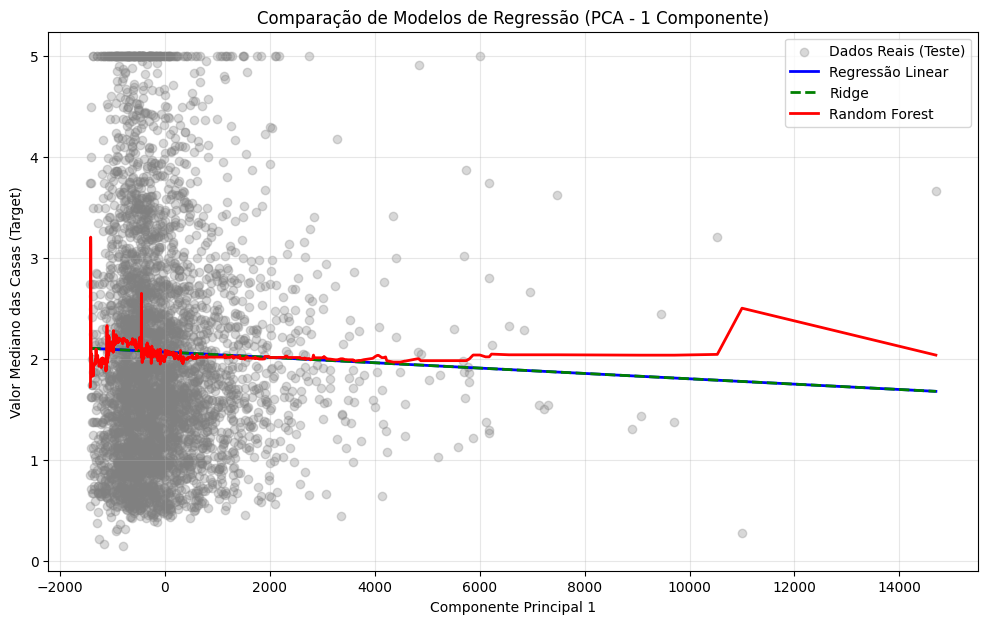

In [8]:
import matplotlib.pyplot as plt
import numpy as np

# Ordenar o eixo X para que as curvas contínuas sejam plotadas corretamente
sort_idx = np.argsort(X_test_pca.flatten())
X_test_sorted = X_test_pca[sort_idx]

plt.figure(figsize=(12, 7))
plt.scatter(X_test_pca, y_test, color='gray', alpha=0.3, label='Dados Reais (Teste)')

# Plot das curvas preditivas
plt.plot(X_test_sorted, lr.predict(X_test_sorted), color='blue', linewidth=2, label='Regressão Linear')
plt.plot(X_test_sorted, ridge.predict(X_test_sorted), color='green', linewidth=2, linestyle='--', label='Ridge')
plt.plot(X_test_sorted, rf.predict(X_test_sorted), color='red', linewidth=2, label='Random Forest')

plt.title('Comparação de Modelos de Regressão (PCA - 1 Componente)')
plt.xlabel('Componente Principal 1')
plt.ylabel('Valor Mediano das Casas (Target)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

###discussão

Os resultados mostram que os modelos apresentaram um desempenho muito fraco ao utilizar apenas um componente principal (PCA) do dataset California Housing.

As métricas de avaliação indicam que tanto a Regressão Linear quanto a Regressão Ridge obtiveram um Erro Quadrático Médio (MSE) de 1.3103 e um R² quase nulo (0.0001). O modelo Random Forest teve um desempenho ligeiramente melhor, mas ainda marginal, com um MSE de 1.3079 e um R² de 0.0019.  

A análise do gráfico evidencia a dificuldade dos modelos em capturar a variância dos dados originais a partir de uma única dimensão. As linhas da Regressão Linear (azul) e da Ridge (verde tracejada) estão praticamente sobrepostas e demonstram uma relação linear muito fraca com os dados reais.

 A curva do Random Forest (vermelha) tenta acompanhar a variação local dos pontos, mas sofre consideravelmente com a dispersão e falta de informatividade do componente principal extraído.   Este cenário ilustra um caso extremo de underfitting causado pela redução drástica de dimensionalidade. A compressão de 8 variáveis independentes (features do dataset) em apenas uma dimensão eliminou a maior parte da informação necessária para prever de forma fiável o valor mediano das casas.

### Referências

1. Scikit-learn Developers. "Real world datasets - California Housing dataset". Disponível em: https://scikit-learn.org/stable/datasets/real_world.html#california-housing-dataset
2. Scikit-learn Developers. "Principal component analysis (PCA)". Disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html
3. Scikit-learn Developers. "Linear Regression". Disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html
4. Scikit-learn Developers. "RandomForestRegressor". Disponível em: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html